In [ ]:
!pip install geopandas

In [ ]:
import geopandas as gpd

gdf_sp = gpd.read_file("SP_Municipios_2025.shp")

In [ ]:
gdf_sp.head()

,CD_MUN,NM_MUN,CD_RGI,NM_RGI,CD_RGINT,NM_RGINT,CD_UF,NM_UF,SIGLA_UF,CD_REGIAO,NM_REGIAO,SIGLA_RG,CD_CONCURB,NM_CONCURB,AREA_KM2,geometry
0,3543402,Ribeirão Preto,350031,Ribeirão Preto,3508,Ribeirão Preto,35,São Paulo,SP,3,Sudeste,SE,3543402,Ribeirão Preto/SP,650.916,"POLYGON ((-47.75591 -21.27076, -47.756 -21.270..."
1,3518859,Guatapará,350031,Ribeirão Preto,3508,Ribeirão Preto,35,São Paulo,SP,3,Sudeste,SE,None,None,413.653,"POLYGON ((-47.88985 -21.49211, -47.88914 -21.4..."
2,3518206,Guararapes,350022,Araçatuba,3506,Araçatuba,35,São Paulo,SP,3,Sudeste,SE,None,None,955.637,"POLYGON ((-50.87363 -21.48917, -50.87333 -21.4..."
3,3510005,Cândido Mota,350014,Assis,3504,Marília,35,São Paulo,SP,3,Sudeste,SE,None,None,595.811,"POLYGON ((-50.34526 -22.91116, -50.3461 -22.91..."
4,3502606,Aparecida d'Oeste,350028,Jales,3507,São José do Rio Preto,35,São Paulo,SP,3,Sudeste,SE,None,None,179.004,"POLYGON ((-50.86389 -20.52668, -50.86428 -20.5..."


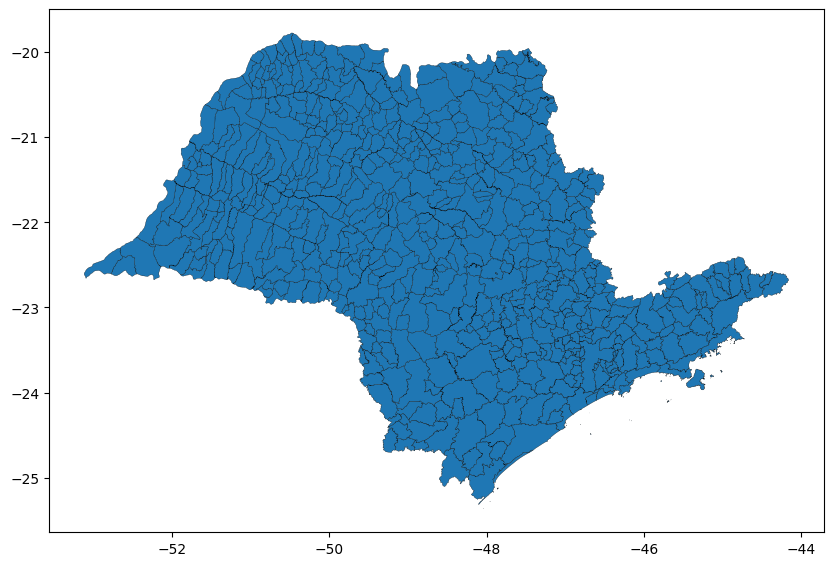

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,10))

gdf_sp.plot(
    ax=ax,
    edgecolor="black",
    linewidth=0.2
)

plt.show()

In [ ]:
print(gdf_sp.crs)

EPSG:4674


In [ ]:
import pandas as pd
from io import StringIO

dados = """
nom_usina_conjunto,val_latitudesecoletora,val_longitudesecoletora
Conj. Boa Hora,-19.881624,-50.397030
Conj. Castilho,-20.790444,-51.529266
Conj. Dracena,-21.450214,-51.587776
Conj. Guaimbê,-21.893809,-49.863684
Conj. Pedranópolis,-20.195849,-50.032683
Conj. Pereira Barreto,-20.620000,-51.300000
"""

usinas_sp = pd.read_csv(StringIO(dados))

print(df)

      nom_usina_conjunto  val_latitudesecoletora  val_longitudesecoletora
0         Conj. Boa Hora              -19.881624               -50.397030
1         Conj. Castilho              -20.790444               -51.529266
2          Conj. Dracena              -21.450214               -51.587776
3          Conj. Guaimbê              -21.893809               -49.863684
4     Conj. Pedranópolis              -20.195849               -50.032683
5  Conj. Pereira Barreto              -20.620000               -51.300000


In [ ]:
usinas_sp.head()

,nom_usina_conjunto,val_latitudesecoletora,val_longitudesecoletora
0,Conj. Boa Hora,-19.881624,-50.397030
1,Conj. Castilho,-20.790444,-51.529266
2,Conj. Dracena,-21.450214,-51.587776
3,Conj. Guaimbê,-21.893809,-49.863684
4,Conj. Pedranópolis,-20.195849,-50.032683


In [ ]:
usinas_sp_geo = gpd.GeoDataFrame(
    usinas_sp,
    geometry=gpd.points_from_xy(
        usinas_sp['val_longitudesecoletora'],
        usinas_sp['val_latitudesecoletora']
    ),
    crs='EPSG:4326'
)

In [ ]:
import pandas as pd

inmet_estacoes = pd.read_csv('/content/Catálogo de Estações Automáticas.csv')
inmet_estacoes.head()

,Nome,UF,Situação,Latitude,Longitude,Altitude,Data de Instalação,Código
0,AFONSO CLAUDIO,ES,Operante,"-20,104167","-41,106944","507,48",23/09/2011,A657
1,ALEGRE,ES,Operante,"-20,750556","-41,488889",138,24/10/2006,A617
2,ALFREDO CHAVES,ES,NaN,NaN,NaN,NaN,NaN,A615
3,ECOPORANGA,ES,Pane,"-18,291389","-40,736389",224,16/03/2017,A631
4,ILHA DE TRINDADE,ES,NaN,NaN,NaN,NaN,NaN,A650


In [ ]:
inmet_estacoes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Nome                162 non-null    object
 1   UF                  162 non-null    object
 2   Situação            146 non-null    object
 3   Latitude            146 non-null    object
 4   Longitude           146 non-null    object
 5   Altitude            146 non-null    object
 6   Data de Instalação  146 non-null    object
 7   Código              162 non-null    object
dtypes: object(8)
memory usage: 10.3+ KB


In [ ]:
inmet_estacoes['Latitude'] = (
    inmet_estacoes['Latitude']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

inmet_estacoes['Longitude'] = (
    inmet_estacoes['Longitude']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [ ]:
inmet_estacoes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Nome                162 non-null    object 
 1   UF                  162 non-null    object 
 2   Situação            146 non-null    object 
 3   Latitude            146 non-null    float64
 4   Longitude           146 non-null    float64
 5   Altitude            146 non-null    object 
 6   Data de Instalação  146 non-null    object 
 7   Código              162 non-null    object 
dtypes: float64(2), object(6)
memory usage: 10.3+ KB


In [ ]:
estacoes_sp = inmet_estacoes[inmet_estacoes['UF']=='SP']
estacoes_sp.head()

,Nome,UF,Situação,Latitude,Longitude,Altitude,Data de Instalação,Código
119,ARIRANHA,SP,Operante,-21.133056,-48.840556,"525,44",12/11/2007,A736
120,AVARE,SP,Operante,-23.101667,-48.941111,"776,36",21/09/2006,A725
121,BARRA BONITA,SP,Operante,-22.471111,-48.557500,"533,68",23/04/2008,A741
122,BARRA DO TURVO,SP,Operante,-24.962778,-48.416389,"659,89",02/07/2008,A746
123,BARRETOS,SP,Operante,-20.559167,-48.545000,"534,36",18/06/2010,A748


In [ ]:
estacoes_sp_geo = gpd.GeoDataFrame(
    estacoes_sp,
    geometry=gpd.points_from_xy(
        estacoes_sp['Longitude'],
        estacoes_sp['Latitude']
    ),
    crs='EPSG:4326'
)

In [ ]:
estacoes_sp_geo = estacoes_sp_geo.to_crs(gdf_sp.crs)

In [ ]:
estacoes_sp_geo.head()

,Nome,UF,Situação,Latitude,Longitude,Altitude,Data de Instalação,Código,geometry
119,ARIRANHA,SP,Operante,-21.133056,-48.840556,"525,44",12/11/2007,A736,POINT (-48.84056 -21.13306)
120,AVARE,SP,Operante,-23.101667,-48.941111,"776,36",21/09/2006,A725,POINT (-48.94111 -23.10167)
121,BARRA BONITA,SP,Operante,-22.471111,-48.557500,"533,68",23/04/2008,A741,POINT (-48.5575 -22.47111)
122,BARRA DO TURVO,SP,Operante,-24.962778,-48.416389,"659,89",02/07/2008,A746,POINT (-48.41639 -24.96278)
123,BARRETOS,SP,Operante,-20.559167,-48.545000,"534,36",18/06/2010,A748,POINT (-48.545 -20.55917)


In [ ]:
print(gdf_sp.crs)
print(estacoes_sp_geo.crs)

EPSG:4674
EPSG:4674


# mapa metodológico

## Figura 1    
Mapa dos municípios de SP + estações INMET

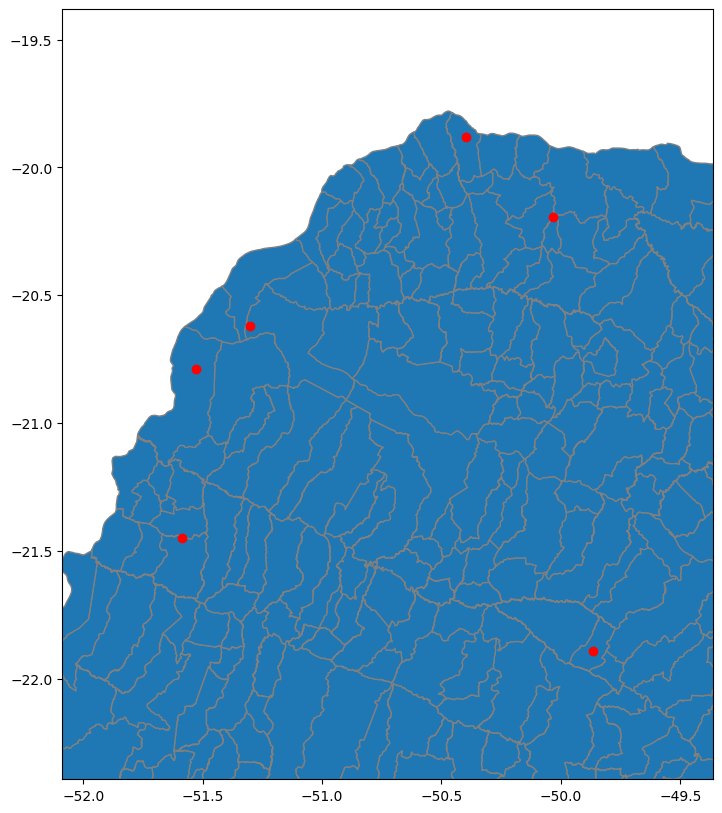

In [ ]:
xmin, ymin, xmax, ymax = usinas_sp_geo.total_bounds

fig, ax = plt.subplots(figsize=(10,10))

gdf_sp.plot(ax=ax, edgecolor='gray')
usinas_sp_geo.plot(ax=ax, color='red')

margem = 0.5

ax.set_xlim(xmin - margem, xmax + margem)
ax.set_ylim(ymin - margem, ymax + margem)

plt.show()

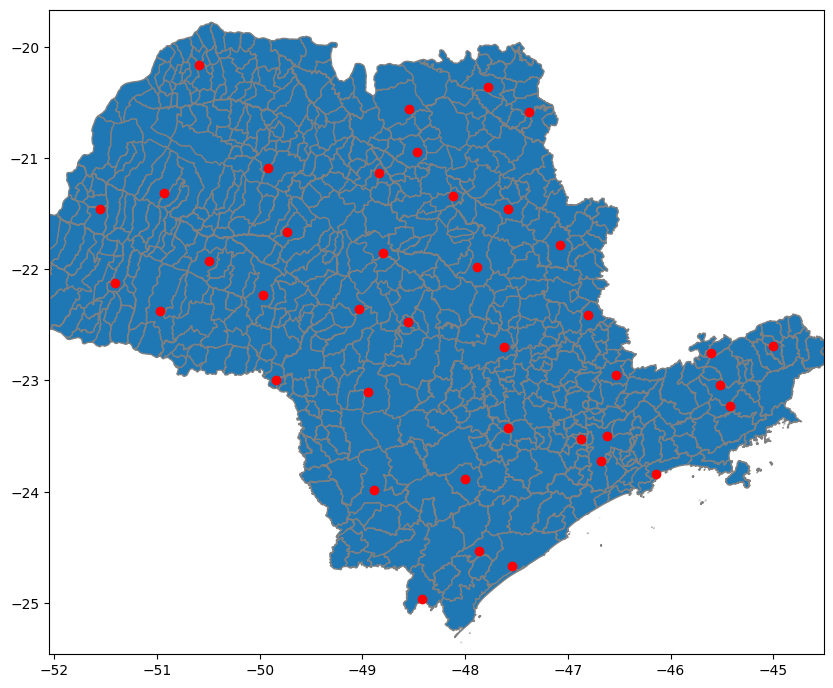

In [ ]:
xmin, ymin, xmax, ymax = estacoes_sp_geo.total_bounds

fig, ax = plt.subplots(figsize=(10,10))

gdf_sp.plot(ax=ax, edgecolor='gray')
estacoes_sp_geo.plot(ax=ax, color='red')

margem = 0.5

ax.set_xlim(xmin - margem, xmax + margem)
ax.set_ylim(ymin - margem, ymax + margem)

plt.show()

# Estações + Usinas Proximas

--- Estações encontradas em um raio de 100km ---
                    Usina              Estação Código  Distância (km)
0          Conj. Boa Hora        CAMPINA VERDE   A519           99.62
1          Conj. Boa Hora                JALES   A733           37.58
2          Conj. Castilho              DRACENA   A762           73.90
3          Conj. Castilho           VALPARAISO   A734           85.42
4           Conj. Dracena              DRACENA   A762            3.78
5           Conj. Dracena  PRESIDENTE PRUDENTE   A707           76.42
6           Conj. Dracena           VALPARAISO   A734           69.68
7           Conj. Guaimbê       JOSE BONIFACIO   A735           89.66
8           Conj. Guaimbê                 LINS   A727           28.52
9           Conj. Guaimbê              MARILIA   A763           39.22
10          Conj. Guaimbê                 TUPA   A768           64.83
11     Conj. Pedranópolis        CAMPINA VERDE   A519           90.48
12     Conj. Pedranópolis                

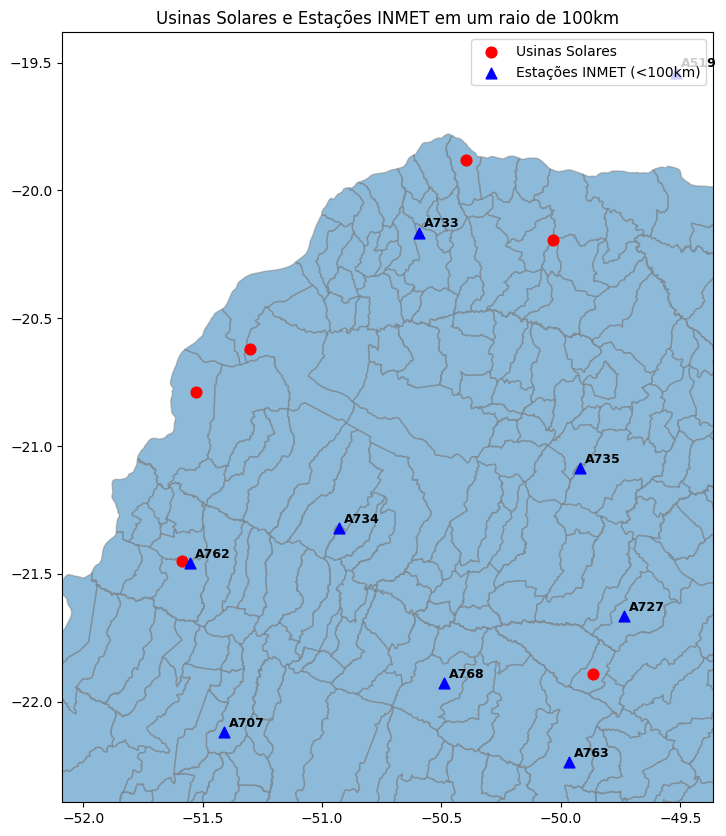

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

# 1. Garantir que as coordenadas do INMET sejam numéricas (tratando possíveis problemas de string/vírgula)
if inmet_estacoes['Latitude'].dtype == 'object':
    inmet_estacoes['Latitude'] = inmet_estacoes['Latitude'].astype(str).str.replace(',', '.').astype(float)
if inmet_estacoes['Longitude'].dtype == 'object':
    inmet_estacoes['Longitude'] = inmet_estacoes['Longitude'].astype(str).str.replace(',', '.').astype(float)

# 2. Converter o dataframe inmet_estacoes para GeoDataFrame (WGS84 - EPSG:4326)
inmet_geo = gpd.GeoDataFrame(
    inmet_estacoes,
    geometry=gpd.points_from_xy(
        inmet_estacoes['Longitude'],
        inmet_estacoes['Latitude']
    ),
    crs='EPSG:4326'
)

# 3. Projetar ambos para UTM (Metros) usando o EPSG:31982 (SIRGAS 2000 / UTM zone 22S)
# Isso permite calcular distâncias em metros de forma geograficamente precisa
usinas_utm = usinas_sp_geo.to_crs(epsg=31982)
inmet_utm = inmet_geo.to_crs(epsg=31982)

# 4. Loop para encontrar estações em um raio de até 100km (100.000 metros)
estacoes_filtradas_list = []
mapeamento_raio = []

for idx, usina in usinas_utm.iterrows():
    # Cria uma área circular de 100km ao redor da usina atual
    buffer_100km = usina.geometry.buffer(100000)

    # Filtra quais estações do INMET caíram dentro dessa área circular
    estacoes_no_raio = inmet_utm[inmet_utm.geometry.within(buffer_100km)]

    if not estacoes_no_raio.empty:
        for _, estacao in estacoes_no_raio.iterrows():
            # Calcula a distância linear exata da usina até a estação (converte metros para km)
            dist_km = usina.geometry.distance(estacao.geometry) / 1000

            mapeamento_raio.append({
                'Usina': usina['nom_usina_conjunto'],
                'Estação': estacao['Nome'],
                'Código': estacao['Código'],
                'Distância (km)': round(dist_km, 2)
            })
            estacoes_filtradas_list.append(estacao['Código'])

# Criar DataFrame com o relatório do raio
df_raio_100km = pd.DataFrame(mapeamento_raio)
print("--- Estações encontradas em um raio de 100km ---")
print(df_raio_100km)

# Filtrar o GeoDataFrame em formato de graus (EPSG:4326) apenas com as estações que passaram no teste
estacoes_encontradas_geo = inmet_geo[inmet_geo['Código'].isin(estacoes_filtradas_list)]

# 5. Plotagem do Mapa Corrigido
xmin, ymin, xmax, ymax = usinas_sp_geo.total_bounds

fig, ax = plt.subplots(figsize=(10, 10))

# Plota o contorno do mapa de SP (Ajuste para a sua variável gdf_sp)
gdf_sp.plot(ax=ax, edgecolor='gray', alpha=0.5)

# Plota as suas Usinas Solares em vermelho
usinas_sp_geo.plot(ax=ax, color='red', marker='o', markersize=60, label='Usinas Solares')

# Plota as Estações do INMET encontradas dentro do raio em azul (triângulos)
if not estacoes_encontradas_geo.empty:
    estacoes_encontradas_geo.plot(ax=ax, color='blue', marker='^', markersize=60, label='Estações INMET (<100km)')

    # Adiciona o texto com o Código de cada estação no mapa
    for idx, row in estacoes_encontradas_geo.iterrows():
        ax.text(row['Longitude'] + 0.02, row['Latitude'] + 0.02, row['Código'], fontsize=9, color='black', weight='bold')

# Limites do mapa com margem
margem = 0.5
ax.set_xlim(xmin - margem, xmax + margem)
ax.set_ylim(ymin - margem, ymax + margem)

plt.legend(loc='upper right')
plt.title("Usinas Solares e Estações INMET em um raio de 100km", fontsize=12)
plt.show()

In [ ]:
df_raio_100km

,Usina,Estação,Código,Distância (km)
0,Conj. Boa Hora,CAMPINA VERDE,A519,99.62
1,Conj. Boa Hora,JALES,A733,37.58
2,Conj. Castilho,DRACENA,A762,73.90
3,Conj. Castilho,VALPARAISO,A734,85.42
4,Conj. Dracena,DRACENA,A762,3.78
5,Conj. Dracena,PRESIDENTE PRUDENTE,A707,76.42
6,Conj. Dracena,VALPARAISO,A734,69.68
7,Conj. Guaimbê,JOSE BONIFACIO,A735,89.66
8,Conj. Guaimbê,LINS,A727,28.52
9,Conj. Guaimbê,MARILIA,A763,39.22
